In [1]:
!pip install imbalanced-learn --quiet


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\Tarek\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from src.preprocessing import load_and_merge_csvs, clean_dataframe, prepare_rf_data
from src.evaluation_multiclass import (
    evaluate_multiclass, plot_confusion_matrix_multiclass, plot_per_class_metric
)
from src.evaluation import log_experiment

df = load_and_merge_csvs(
    data_dir="../../data/raw/CIC2017",
    output_parquet="../../data/processed/merged_raw.parquet"
)
df = clean_dataframe(df)                      # <- this line was missing
print(df.shape, 'label' in df.columns)        # should print True

X, y, label_encoder = prepare_rf_data(df)
print(X.shape, np.bincount(y))
print(dict(zip(label_encoder.classes_, np.bincount(y))))   # samples per attack type

Loading fast merged raw data from Parquet...
(2520798, 79) True
(425741, 78) [  1948 128014  10286 172846   5228   5385   5931     11     36  90694
   3219   1470     21    652]
{'Bot': np.int64(1948), 'DDoS': np.int64(128014), 'DoS GoldenEye': np.int64(10286), 'DoS Hulk': np.int64(172846), 'DoS Slowhttptest': np.int64(5228), 'DoS slowloris': np.int64(5385), 'FTP-Patator': np.int64(5931), 'Heartbleed': np.int64(11), 'Infiltration': np.int64(36), 'PortScan': np.int64(90694), 'SSH-Patator': np.int64(3219), 'Web Attack � Brute Force': np.int64(1470), 'Web Attack � Sql Injection': np.int64(21), 'Web Attack � XSS': np.int64(652)}


In [3]:
from src.resampling import cap_majority_classes, oversample_rare_classes, class_count_report

print(class_count_report(y, label_encoder))

                         class   count
0                     DoS Hulk  172846
1                         DDoS  128014
2                     PortScan   90694
3                DoS GoldenEye   10286
4                  FTP-Patator    5931
5                DoS slowloris    5385
6             DoS Slowhttptest    5228
7                  SSH-Patator    3219
8                          Bot    1948
9     Web Attack � Brute Force    1470
10            Web Attack � XSS     652
11                Infiltration      36
12  Web Attack � Sql Injection      21
13                  Heartbleed      11


In [4]:
# 1. split FIRST (real data only)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# 2. resample the TRAINING set only
X_b, y_b = cap_majority_classes(X_train, y_train, cap=20_000)
X_b, y_b, report = oversample_rare_classes(
    X_b, y_b, target_per_class=2_000, max_multiplier=20, label_encoder=label_encoder)

# 3. train on (X_b, y_b); evaluate on the untouched X_val / y_val

Oversampled classes (training set only):
                            before  after
class                                    
Heartbleed                       8    160
Web Attack � Sql Injection      15    300
Infiltration                    25    500
Web Attack � XSS               456   2000
Web Attack � Brute Force      1029   2000
Bot                           1364   2000


In [5]:
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(X_b, y_b)
# evaluate on the ORIGINAL X_val / y_val, never on resampled data

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

===== Random Forest (val) — Multiclass Evaluation =====
accuracy        : 0.9976
macro_auc_roc   : 0.9875
macro_auc_pr    : 0.8785
macro_precision : 0.8633
macro_recall    : 0.8506
macro_f1        : 0.8558
weighted_f1     : 0.9975

Per-class results:
                     class  support  auc_roc  auc_pr  precision  recall  f1_score
                       Bot      292   1.0000  1.0000     1.0000  0.9966    0.9983
                      DDoS    19202   1.0000  1.0000     0.9999  1.0000    0.9999
             DoS GoldenEye     1543   0.9997  0.9987     0.9935  0.9968    0.9951
                  DoS Hulk    25927   0.9999  0.9998     0.9993  0.9997    0.9995
          DoS Slowhttptest      784   0.9994  0.9983     1.0000  0.9923    0.9962
             DoS slowloris      808   1.0000  0.9998     0.9938  0.9963    0.9951
               FTP-Patator      889   1.0000  1.0000     1.0000  1.0000    1.0000
                Heartbleed        2   1.0000  1.0000     1.0000  1.0000    1.0000
           

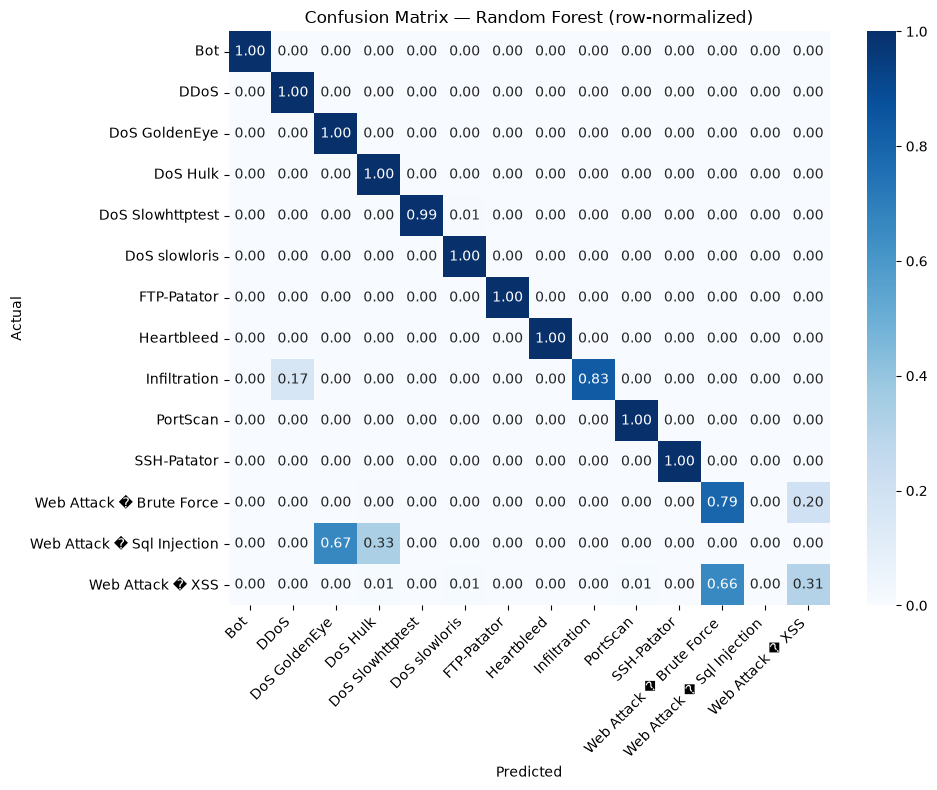

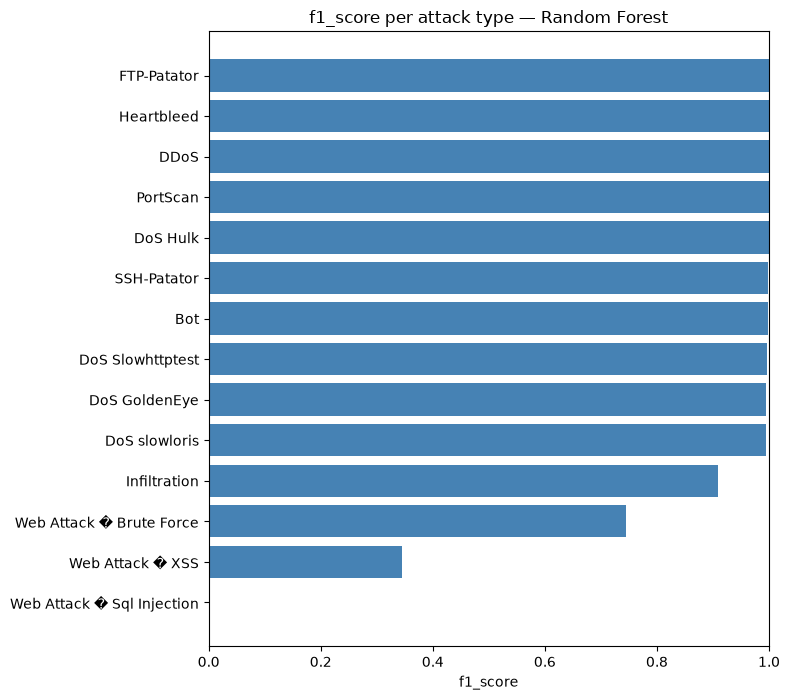

In [6]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",   # handles the imbalance between attack types
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

class_names = label_encoder.inverse_transform(rf.classes_)

y_pred  = rf.predict(X_val)
y_proba = rf.predict_proba(X_val)

summary, per_class = evaluate_multiclass(
    y_val, y_pred, y_proba, rf.classes_, class_names, model_name="Random Forest (val)")

plot_confusion_matrix_multiclass(y_val, y_pred, rf.classes_, class_names, "Random Forest")
plot_per_class_metric(per_class, "f1_score", "Random Forest")


In [6]:
log_experiment("../experiments/results_log.csv", "RandomForest",
               params={"n_estimators": 200, "class_weight": "balanced_subsample"},
               metrics=summary)

Logged experiment for RandomForest -> ../experiments/results_log.csv


In [8]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from src.resampling import cap_majority_classes

# ~48k rows: giants capped at 8,000, every rare-class row kept (real data only, no SMOTE)
X_tune, y_tune = cap_majority_classes(X_train, y_train, cap=8_000)

param_grid = {
    "max_depth": [None, 20, 40],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"],
} 

web_ids = [i for i, n in enumerate(label_encoder.classes_) if "Web Attack" in n]
web_f1 = make_scorer(f1_score, labels=web_ids, average="macro", zero_division=0)

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=42),
    param_grid,
    scoring={"macro_f1": "f1_macro", "web_f1": web_f1},
    refit=False,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    verbose=2,
)
grid.fit(X_tune, y_tune)

res = pd.DataFrame(grid.cv_results_)[
    ["params", "mean_test_macro_f1", "mean_test_web_f1", "std_test_web_f1"]
].sort_values("mean_test_web_f1", ascending=False)
display(res)
best_params = res.iloc[0]["params"]     # best_params_ doesn't exist with multi-metric + refit=False

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1; total time=   4.3s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1; total time=   3.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1; total time=   3.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2; total time=   3.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2; total time=   3.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2; total time=   3.6s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=5; total time=   3.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=5; total time=   2.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=5; total time=   2.9s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=1; total time=   2.6s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=1; total time=   2.9s
[CV] END max_depth=None, m

,params,mean_test_macro_f1,mean_test_web_f1,std_test_web_f1
10,"{'max_depth': 20, 'max_features': 'log2', 'min...",0.910271,0.625169,0.004269
6,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.907617,0.612271,0.054160
0,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.906887,0.608619,0.049574
12,"{'max_depth': 40, 'max_features': 'sqrt', 'min...",0.906501,0.606817,0.050469
4,"{'max_depth': None, 'max_features': 'log2', 'm...",0.907946,0.606817,0.034243
16,"{'max_depth': 40, 'max_features': 'log2', 'min...",0.907882,0.606517,0.034111
13,"{'max_depth': 40, 'max_features': 'sqrt', 'min...",0.904492,0.598303,0.028810
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.904403,0.597934,0.028639
7,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.901808,0.585536,0.032588
9,"{'max_depth': 20, 'max_features': 'log2', 'min...",0.901728,0.585050,0.056263


In [9]:
params_df = pd.json_normalize(res["params"].tolist())   # .tolist() drops the scrambled index
out = pd.concat([params_df, res.drop(columns="params").reset_index(drop=True)], axis=1)

# readable max_depth: None shows as "None" instead of an empty cell, 20.0 becomes 20
out["max_depth"] = out["max_depth"].map(lambda v: "None" if pd.isna(v) else int(v))

print(out.head(3))      # first row should be max_depth 20, log2, min_samples_leaf 2, 0.9103, 0.6252
# out.to_csv("../experiments/rf_grid_search_results.csv", index=False)

  max_depth max_features  min_samples_leaf  mean_test_macro_f1  \
0        20         log2                 2            0.910271   
1        20         sqrt                 1            0.907617   
2      None         sqrt                 1            0.906887   

   mean_test_web_f1  std_test_web_f1  
0          0.625169         0.004269  
1          0.612271         0.054160  
2          0.608619         0.049574  


In [10]:
best_params = res.iloc[0]["params"]          # from the grid search table
print(best_params)

# use whichever training data won on validation:
X_fit, y_fit = X_b, y_b                    # strategy B / C (cap + SMOTE)

final_rf = RandomForestClassifier(
    n_estimators=300,                        # from your n_estimators curve
    class_weight="balanced_subsample",       # remove this line if your winner was strategy B
    n_jobs=-1,
    random_state=42,
    **best_params,
)
final_rf.fit(X_fit, y_fit)

{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 2}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or

Comparison between 3 strategies:
- strategy A: No resampling. The model is told to treat rare-class mistakes as more costly.
- strategy B: Rebalances by changing the data only.(giants capped at 20,000 + SMOTE on rare classes)	
- strategy C: Resampled data and class weights together.(same as B)

In [12]:
from sklearn.ensemble import RandomForestClassifier
from src.resampling import cap_majority_classes, oversample_rare_classes

# 1. resampled training set for B and C (training data only)
X_b, y_b = cap_majority_classes(X_train, y_train, cap=20_000)
X_b, y_b, report = oversample_rare_classes(
    X_b, y_b, target_per_class=2_000, max_multiplier=20, label_encoder=label_encoder)

# 2. one helper: train with a given dataset and class_weight, score on VALIDATION
def fit_eval(name, X_tr, y_tr, class_weight=None):
    rf = RandomForestClassifier(n_estimators=200, class_weight=class_weight,
                                n_jobs=-1, random_state=42, **best_params)
    rf.fit(X_tr, y_tr)
    names = label_encoder.inverse_transform(rf.classes_)
    summary, per_class = evaluate_multiclass(
        y_val, rf.predict(X_val), rf.predict_proba(X_val),
        rf.classes_, names, name, verbose=False)
    return summary, per_class

# 3. the three strategies
runs = {
    "A_class_weight_only": fit_eval("A", X_train, y_train, "balanced_subsample"),
    "B_cap+SMOTE":         fit_eval("B", X_b, y_b),
    "C_cap+SMOTE+weights": fit_eval("C", X_b, y_b, "balanced_subsample"),
}

# 4. comparison tables
comparison = pd.DataFrame({k: v[0] for k, v in runs.items()}).T[
    ["macro_f1", "macro_auc_pr", "macro_recall", "accuracy"]]
recall_by_class = pd.DataFrame(
    {k: v[1].set_index("class")["recall"] for k, v in runs.items()})

display(comparison.round(4))
display(recall_by_class.round(3))

# 5. save as evidence for the report
# comparison.to_csv("../experiments/strategy_comparison.csv")
# recall_by_class.to_csv("../experiments/recall_by_class.csv")

Oversampled classes (training set only):
                            before  after
class                                    
Heartbleed                       8    160
Web Attack � Sql Injection      15    300
Infiltration                    25    500
Web Attack � XSS               456   2000
Web Attack � Brute Force      1029   2000
Bot                           1364   2000


,macro_f1,macro_auc_pr,macro_recall,accuracy
A_class_weight_only,0.8641,0.8758,0.8617,0.9975
B_cap+SMOTE,0.8576,0.8739,0.8617,0.9973
C_cap+SMOTE+weights,0.8617,0.8769,0.8604,0.9972


,A_class_weight_only,B_cap+SMOTE,C_cap+SMOTE+weights
class,,,
Bot,0.997,0.993,0.997
DDoS,1.000,1.000,1.000
DoS GoldenEye,0.998,0.999,1.000
DoS Hulk,1.000,0.999,0.999
DoS Slowhttptest,0.990,0.991,0.990
DoS slowloris,0.995,0.996,0.996
FTP-Patator,1.000,0.997,0.999
Heartbleed,1.000,1.000,1.000
Infiltration,0.833,0.833,0.833


In [13]:
import joblib, os
from sklearn.ensemble import RandomForestClassifier

# best hyperparameters from the grid search table
best_params = res.iloc[0]["params"]
print(best_params)
# if the notebook was restarted and `res` is gone, set them by hand (check them against your saved CSV):
# best_params = {"max_depth": 20, "max_features": "log2", "min_samples_leaf": 2}

final_rf = RandomForestClassifier(
    n_estimators=300,                    # use the value your n_estimators curve picked
    class_weight="balanced_subsample",   # strategy A
    n_jobs=-1,
    random_state=42,
    **best_params,
)
final_rf.fit(X_train, y_train)           # original, un-resampled training data

# sanity check on validation (not the final test)
class_names = label_encoder.inverse_transform(final_rf.classes_)
summary_val, per_class_val = evaluate_multiclass(
    y_val, final_rf.predict(X_val), final_rf.predict_proba(X_val),
    final_rf.classes_, class_names, model_name="Random Forest A (validation)")


{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 2}
===== Random Forest A (validation) — Multiclass Evaluation =====
accuracy        : 0.9975
macro_auc_roc   : 0.9998
macro_auc_pr    : 0.8771
macro_precision : 0.8676
macro_recall    : 0.8594
macro_f1        : 0.8624
weighted_f1     : 0.9975

Per-class results:
                     class  support  auc_roc  auc_pr  precision  recall  f1_score
                       Bot      292   1.0000  1.0000     1.0000  0.9966    0.9983
                      DDoS    19202   1.0000  1.0000     0.9999  1.0000    1.0000
             DoS GoldenEye     1543   1.0000  1.0000     0.9923  0.9981    0.9952
                  DoS Hulk    25927   1.0000  1.0000     0.9993  0.9996    0.9995
          DoS Slowhttptest      784   1.0000  0.9985     0.9987  0.9898    0.9942
             DoS slowloris      808   1.0000  0.9998     0.9938  0.9950    0.9944
               FTP-Patator      889   1.0000  1.0000     1.0000  1.0000    1.0000
                Hea

In [14]:
def cid(sub): return [i for i, n in enumerate(label_encoder.classes_) if sub in n][0]

groups = {
    "SQLi (train)": X_train[y_train == cid("Sql")],
    "SQLi (val)":   X_val[y_val == cid("Sql")],
    "GoldenEye":    X_train[y_train == cid("GoldenEye")],
    "Hulk":         X_train[y_train == cid("Hulk")],
    "Brute Force":  X_train[y_train == cid("Brute")],
    "XSS":          X_train[y_train == cid("XSS")],
}
cols = [c for c in ["flow duration", "total fwd packets", "total backward packets",
                    "total length of fwd packets", "flow bytes/s",
                    "fwd packet length mean", "flow iat mean", "destination port"]
        if c in X_train.columns]

display(pd.DataFrame({k: v[cols].median() for k, v in groups.items()}).round(1))

# does the model at least recognize the SQLi rows it was trained on?
sqli_train = X_train[y_train == cid("Sql")]
print("SQLi training recall:", (final_rf.predict(sqli_train) == cid("Sql")).mean())

,SQLi (train),SQLi (val),GoldenEye,Hulk,Brute Force,XSS
flow duration,5006168.0,5012479.0,11580265.5,86329899.0,5562297.0,5381989.0
total fwd packets,4.0,5.0,7.0,6.0,3.0,3.0
total backward packets,3.0,4.0,5.0,6.0,1.0,1.0
total length of fwd packets,523.0,599.0,377.0,354.0,0.0,0.0
flow bytes/s,453.7,946.4,655.4,123.9,0.0,0.0
fwd packet length mean,115.0,100.0,52.6,53.8,0.0,0.0
flow iat mean,715055.4,556942.1,1118196.0,7207270.5,1808410.3,1788259.2
destination port,80.0,80.0,80.0,80.0,80.0,80.0


SQLi training recall: 1.0


In [15]:
# # save the model together with its label encoder
# os.makedirs("../models", exist_ok=True)
# joblib.dump({"model": final_rf, "label_encoder": label_encoder},
#             "../models/random_forest_final.joblib", compress=3)

In [16]:
# best = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
#                               n_jobs=-1, random_state=42, **grid.best_params_)
# best.fit(X_train, y_train)

In [17]:
# from sklearn.model_selection import RandomizedSearchCV

# param_dist = {
#     "n_estimators": [100, 200, 300],
#     "max_depth": [None, 20, 40],
#     "min_samples_leaf": [1, 2, 5],
#     "max_features": ["sqrt", "log2"],
# }
# # tune on a subsample so each trial takes seconds, not minutes
# idx = np.random.RandomState(42).choice(len(X_train), size=min(100_000, len(X_train)), replace=False)

# search = RandomizedSearchCV(
#     RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=42),
#     param_dist, n_iter=10, scoring="f1_macro", cv=3, random_state=42, verbose=1)
# search.fit(X_train.iloc[idx], y_train[idx])
# print(search.best_params_)